# EDA A: Thời gian và ngày lễ

Các phép kiểm tra dùng chung nằm trong `src/eda/helpers.py`. Notebook chỉ giữ phần phân tích và nhận xét.

In [1]:
from pathlib import Path
import sys
project_root = next((folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / 'data/Metro_Interstate_Traffic_Volume.csv').is_file()))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import TimeSeriesSplit
from src.eda import helpers as eda_tools
from src.features import CONFIG_A, CONFIG_B, CONFIG_C, HISTORY_FEATURES, WEATHER_GROUPS
SEED = eda_tools.SEED
MIN_GROUP = eda_tools.MIN_GROUP
MIN_HISTORY = eda_tools.MIN_HISTORY

In [2]:
context = eda_tools.load_context(project_root)
train = context['train']

In [3]:
hour_profiles = train.groupby(['is_weekend', 'hour']).traffic_volume.agg(mean='mean', n='size').reset_index()
peak_hours = hour_profiles.loc[hour_profiles.groupby('is_weekend')['mean'].idxmax()]
work_peak = int(peak_hours.loc[peak_hours.is_weekend.eq(0), 'hour'].iloc[0])
weekend_peak = int(peak_hours.loc[peak_hours.is_weekend.eq(1), 'hour'].iloc[0])
display(Markdown(f'**Mục tiêu:** khảo sát nhịp thời gian và ngày lễ để xây dựng A12.  \n**Kết luận chính:** giờ có trung bình cao nhất là {work_peak}h ở ngày làm việc và {weekend_peak}h ở cuối tuần, trên {len(train):,} giờ train.  \n**Quyết định:** giữ A12 làm cấu hình tham chiếu, kiểm tra thông tin trùng và chưa chọn feature bằng test.'))

**Mục tiêu:** khảo sát nhịp thời gian và ngày lễ để xây dựng A12.  
**Kết luận chính:** giờ có trung bình cao nhất là 16h ở ngày làm việc và 13h ở cuối tuần, trên 28,402 giờ train.  
**Quyết định:** giữ A12 làm cấu hình tham chiếu, kiểm tra thông tin trùng và chưa chọn feature bằng test.

## 1. Câu hỏi và giả thuyết

Giờ có lưu lượng cao nhất có giống nhau giữa ngày làm việc và cuối tuần không? Ngày lễ khác ngày thường thế nào khi so cùng thứ và giờ?

## 2. Ý tưởng tách đặc trưng

Giờ, thứ và tháng giúp mô tả nhịp giao thông. Cặp sin/cos giữ sự liền nhau giữa đầu và cuối chu kỳ. Cờ cao điểm dùng định nghĩa đã có, chưa điều chỉnh theo kết quả EDA.

## 3. Đặc trưng được tạo

In [4]:
display(eda_tools.feature_spec(context, 'A'))

,feature,formula,dtype,source,missing_rule,n
0,hour,date_time.dt.hour,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
1,day_of_week,date_time.dt.dayofweek (Monday=0),int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
2,month,date_time.dt.month,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
3,is_weekend,day_of_week >= 5,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
4,is_rush_hour,"hour thuộc (6, 7, 8, 15, 16, 17) và is_weekend=0",int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
5,hour_sin,sin(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
6,hour_cos,cos(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
7,day_of_week_sin,sin(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
8,day_of_week_cos,cos(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
9,month_sin,sin(2*pi*(month-1)/12),float64,date_time,không thiếu sau kiểm tra timestamp,28402


## 4. Chất lượng và phân phối

In [5]:
eda_tools.audit_context(context)

,item,observed,expected,matches,n
0,rows,48204,48204,True,48204
1,columns,9,9,True,48204
2,unique_timestamps,40575,40575,True,48204
3,extra_timestamp_rows,7629,7629,True,48204
4,missing_hours,11976,11976,True,48204


,split,start,end,n
0,train,2012-10-02 09:00:00,2017-05-10 04:00:00,28402
1,validation,2017-05-10 05:00:00,2018-01-19 14:00:00,6086
2,test,2018-01-19 15:00:00,2018-09-30 23:00:00,6087


Các số kiểm toán khớp mốc cung cấp; phân tích feature bên dưới dùng **28,402 giờ train**, chưa chấm validation/test. Timestamp không có timezone; chưa phân tích DST (đổi giờ mùa hè). Nhãn lễ lấy theo ngày có ghi trong CSV, chưa tự bổ sung lịch ngoài. Nhãn hiếm đánh dấu khi n < 30; đây là ngưỡng mô tả, không phải kiểm định.

In [6]:
display(eda_tools.quality(train, CONFIG_A))

,feature,missing,missing_pct,minimum,maximum,distinct,n
0,hour,0,0.0,0.000000,23.000000,24,28402
1,day_of_week,0,0.0,0.000000,6.000000,7,28402
2,month,0,0.0,1.000000,12.000000,12,28402
3,is_weekend,0,0.0,0.000000,1.000000,2,28402
4,is_rush_hour,0,0.0,0.000000,1.000000,2,28402
5,hour_sin,0,0.0,-1.000000,1.000000,21,28402
6,hour_cos,0,0.0,-1.000000,1.000000,22,28402
7,day_of_week_sin,0,0.0,-0.974928,0.974928,7,28402
8,day_of_week_cos,0,0.0,-0.900969,1.000000,7,28402
9,month_sin,0,0.0,-1.000000,1.000000,11,28402


In [7]:
flag_counts = pd.concat([train.groupby(f).traffic_volume.size().rename('n').reset_index().rename(columns={f: 'value'}).assign(feature=f) for f in ['is_weekend', 'is_rush_hour', 'is_holiday']], ignore_index=True)
flag_counts['small_group'] = flag_counts.n.lt(MIN_GROUP)
display(flag_counts)

,value,n,feature,small_group
0,0,20294,is_weekend,False
1,1,8108,is_weekend,False
2,0,23384,is_rush_hour,False
3,1,5018,is_rush_hour,False
4,0,27558,is_holiday,False
5,1,844,is_holiday,False


## 5. Quan hệ với mục tiêu

Với `hour`, `day_of_week`, `month`, ta xem trung bình và n theo nhóm; Pearson giữa mã số chu kỳ thô và target không phù hợp để trả lời câu hỏi này. Các bảng feature–feature ở sau chỉ phục vụ chẩn đoán trùng thông tin.

In [8]:
for feature in ['hour', 'day_of_week', 'month']:
    display(Markdown(f'**Trung bình theo `{feature}`:**'))
    display(eda_tools.grouped(train, feature))

**Trung bình theo `hour`:**

,hour,mean,median,n,small_group
0,0,830.931687,676.0,1215,False
1,1,517.853577,422.5,1202,False
2,2,392.640067,317.0,1203,False
3,3,371.579038,360.0,1164,False
4,4,688.785297,788.0,1197,False
5,5,2058.020374,2601.5,1178,False
6,6,4161.245748,5394.5,1176,False
7,7,4756.176672,6003.5,1166,False
8,8,4573.059222,5417.0,1182,False
9,9,4367.263484,4827.0,1131,False


**Trung bình theo `day_of_week`:**

,day_of_week,mean,median,n,small_group
0,0,3312.031426,3709.0,4073,False
1,1,3523.682743,4177.0,3981,False
2,2,3579.918493,4285.0,4061,False
3,3,3622.922280,4261.0,4053,False
4,4,3637.539021,4171.5,4126,False
5,5,2786.074944,3001.0,4043,False
6,6,2388.502829,2301.0,4065,False


**Trung bình theo `month`:**

,month,mean,median,n,small_group
0,1,3045.009948,3037.0,2513,False
1,2,3222.383224,3322.0,2432,False
2,3,3363.978091,3608.0,2556,False
3,4,3394.167223,3520.0,2697,False
4,5,3372.081554,3432.5,2342,False
5,6,3411.760679,3556.5,1826,False
6,7,3217.480343,3252.5,2798,False
7,8,3399.288029,3629.0,2222,False
8,9,3276.075209,3412.0,1795,False
9,10,3360.106345,3652.0,2238,False


,is_weekend,hour,mean,n
0,0,0,648.722477,872
1,0,1,397.232394,852
2,0,2,303.032445,863
3,0,3,361.434886,837
4,0,4,815.202814,853
5,0,5,2644.317746,834
6,0,6,5363.269504,846
7,0,7,6061.612591,826
8,0,8,5500.364397,837
9,0,9,4879.954208,808


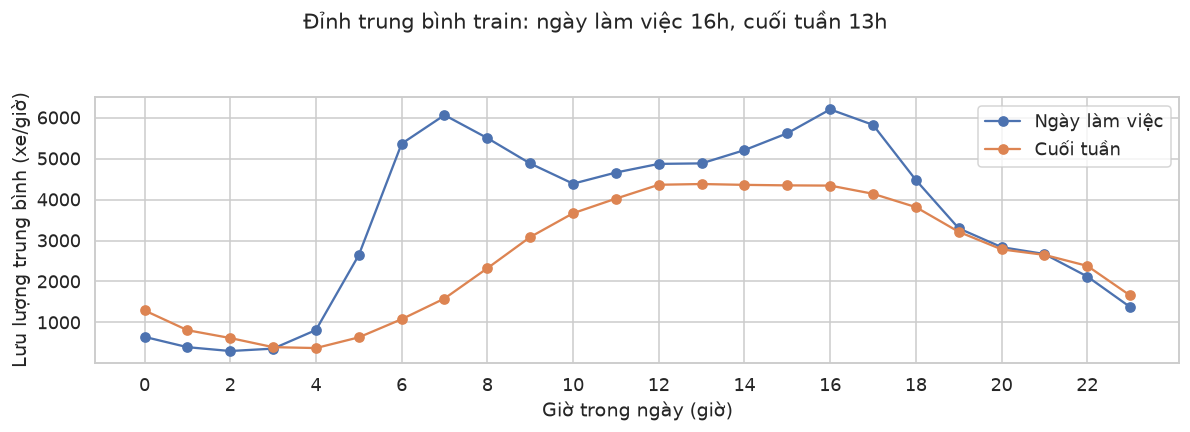

So hai đường ở cùng giờ, đọc cùng n trong bảng phía trên. Đây là thống kê trên giờ quan sát; độ phủ không đều có thể ảnh hưởng trung bình.

In [9]:
display(hour_profiles)
fig, ax = plt.subplots(figsize=(11, 4))
for flag, label in [(0, 'Ngày làm việc'), (1, 'Cuối tuần')]:
    part = hour_profiles.loc[hour_profiles.is_weekend.eq(flag)]
    ax.plot(part.hour, part['mean'], marker='o', label=label)
ax.set(xlabel='Giờ trong ngày (giờ)', ylabel='Lưu lượng trung bình (xe/giờ)', xticks=range(0, 24, 2))
ax.legend()
eda_tools.figure(context, 'A', 1, 'weekday_weekend', fig, f'Đỉnh trung bình train: ngày làm việc {work_peak}h, cuối tuần {weekend_peak}h', 'So hai đường ở cùng giờ, đọc cùng n trong bảng phía trên. Đây là thống kê trên giờ quan sát; độ phủ không đều có thể ảnh hưởng trung bình.')

,day_of_week,hour,n
0,0,0,177
1,0,1,168
2,0,2,174
3,0,3,168
4,0,4,170
...,...,...,...
163,6,19,166
164,6,20,173
165,6,21,171
166,6,22,174


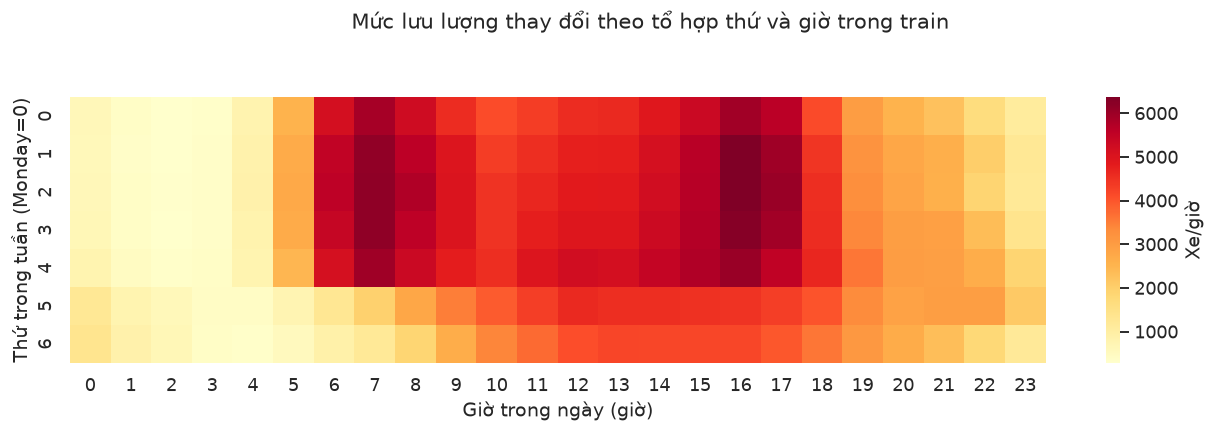

Màu đậm hơn biểu thị trung bình cao hơn. Mỗi ô có n riêng trong bảng; chưa thể quy chênh lệch cho nguyên nhân đi làm.

In [10]:
means = train.pivot_table(index='day_of_week', columns='hour', values='traffic_volume', aggfunc='mean')
counts = train.pivot_table(index='day_of_week', columns='hour', values='traffic_volume', aggfunc='size')
group_sizes = counts.stack().rename('n').reset_index()
display(group_sizes)
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(means, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Xe/giờ'})
ax.set(xlabel='Giờ trong ngày (giờ)', ylabel='Thứ trong tuần (Monday=0)')
eda_tools.figure(context, 'A', 2, 'weekday_hour_heatmap', fig, 'Mức lưu lượng thay đổi theo tổ hợp thứ và giờ trong train', 'Màu đậm hơn biểu thị trung bình cao hơn. Mỗi ô có n riêng trong bảng; chưa thể quy chênh lệch cho nguyên nhân đi làm.')

Bootstrap lấy lại các khối 7 ngày để ước lượng khoảng tin cậy. Nhóm ít mẫu cần đọc thận trọng.

In [11]:
flag_effects = pd.DataFrame([eda_tools.binary_effect(train, f) for f in ['is_weekend', 'is_rush_hour', 'is_holiday']])
display(flag_effects)

,feature,n0,n1,mean_difference,ci_low,ci_high,bootstrap_valid,small_group,n
0,is_weekend,20294,8108,-948.675939,-997.514609,-907.528063,400,False,28402
1,is_rush_hour,23384,5018,3032.843850,2977.674225,3094.377636,400,False,28402
2,is_holiday,27558,844,-743.644461,-963.801250,-553.857477,400,False,28402


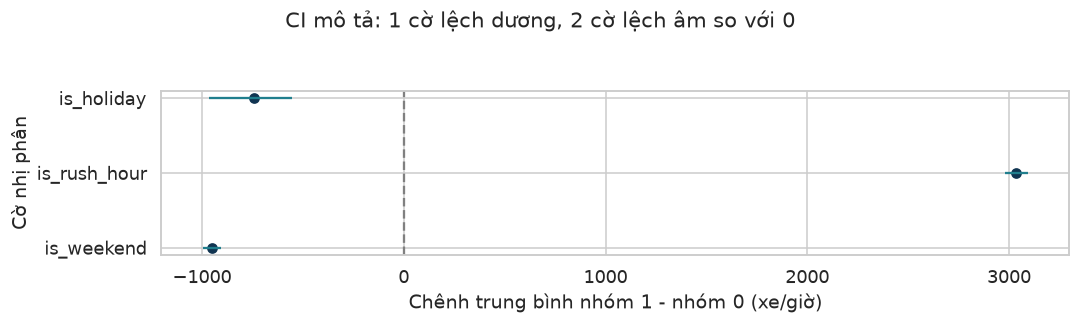

Điểm là chênh trung bình, đoạn ngang là CI bootstrap khối 7 ngày 95%. Đọc cùng n0/n1; nhóm quá ít mẫu hoặc không có biến thiên không cho CI đáng tin cậy. Chênh này chưa điều chỉnh lịch và không chứng minh tác động nhân quả.

In [12]:
eda_tools.binary_plot(context, 'A', flag_effects, 3)

In [13]:
holiday_pairs, holiday_result = eda_tools.matched_holidays(train)
display(holiday_pairs)
display(Markdown(f"Sau ghép cùng thứ và giờ, chênh lễ - thường là {holiday_result['difference']:.1f} xe/giờ; CI bootstrap theo ngày sự kiện [{holiday_result['low']:.1f}, {holiday_result['high']:.1f}], n={holiday_result['n']:,} giờ lễ thuộc {holiday_result['n_days']} ngày. Ghép này chưa kiểm soát mùa/năm hoặc sự kiện khác; không kết luận nhân quả."))

,day_of_week,hour,holiday_mean,normal_mean,difference,n0,n,small_group
0,0,0,758.476190,598.397436,160.078755,156,21,True
1,0,1,453.526316,366.147651,87.378665,149,19,True
2,0,2,343.700000,280.675325,63.024675,154,20,True
3,0,3,329.476190,336.367347,-6.891156,147,21,True
4,0,4,599.500000,818.280000,-218.780000,150,20,True
...,...,...,...,...,...,...,...,...
114,4,19,3094.333333,3613.707602,-519.374269,171,3,True
115,4,20,2480.333333,3004.585799,-524.252465,169,3,True
116,4,21,2451.500000,2964.158824,-512.658824,170,4,True
117,4,22,2458.000000,2678.523529,-220.523529,170,3,True


Sau ghép cùng thứ và giờ, chênh lễ - thường là -953.3 xe/giờ; CI bootstrap theo ngày sự kiện [-1186.5, -719.7], n=844 giờ lễ thuộc 38 ngày. Ghép này chưa kiểm soát mùa/năm hoặc sự kiện khác; không kết luận nhân quả.

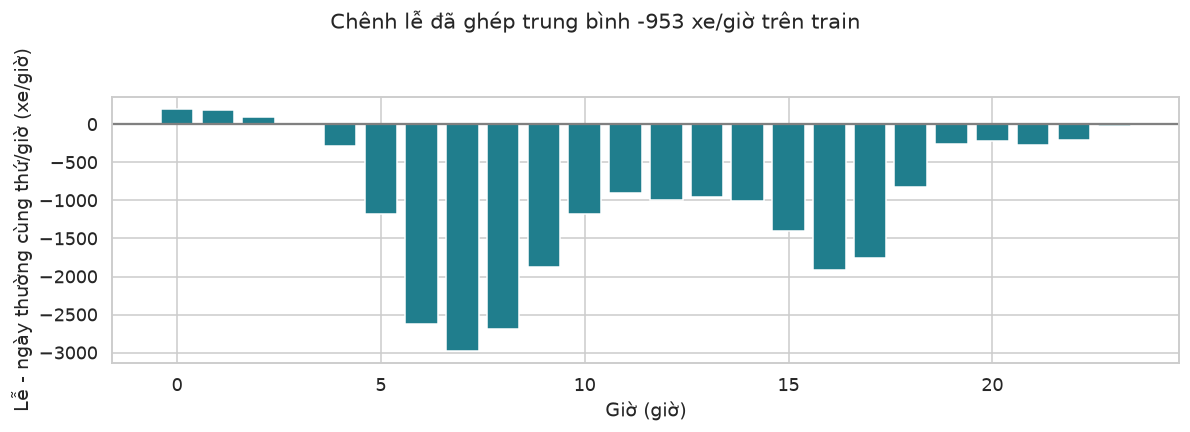

Mỗi cột tổng hợp các cặp cùng giờ, có trọng số theo số giờ lễ. Bảng phía trên cho n lễ và n0 đối chứng; một số nhóm có ít ngày sự kiện.

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
by_hour = holiday_pairs.groupby('hour').apply(lambda z: np.average(z.difference, weights=z.n), include_groups=False)
ax.bar(by_hour.index, by_hour.values, color='#207E8D')
ax.axhline(0, color='grey')
ax.set(xlabel='Giờ (giờ)', ylabel='Lễ - ngày thường cùng thứ/giờ (xe/giờ)')
eda_tools.figure(context, 'A', 4, 'holiday_matched', fig, f"Chênh lễ đã ghép trung bình {holiday_result['difference']:.0f} xe/giờ trên train", 'Mỗi cột tổng hợp các cặp cùng giờ, có trọng số theo số giờ lễ. Bảng phía trên cho n lễ và n0 đối chứng; một số nhóm có ít ngày sự kiện.')

VIF giúp nhận diện feature trùng thông tin tuyến tính; không dùng riêng chỉ số này để bỏ cột.

In [15]:
corr_a, vif_a = eda_tools.correlation_and_vif(train, CONFIG_A)
display(vif_a)

,feature,VIF,note,n
0,hour,2.555155,chưa vượt ngưỡng mô tả 5,28402
1,day_of_week,8.588969,đa cộng tuyến tuyến tính,28402
2,month,2.623266,chưa vượt ngưỡng mô tả 5,28402
3,is_weekend,8.267764,đa cộng tuyến tuyến tính,28402
4,is_rush_hour,1.174368,chưa vượt ngưỡng mô tả 5,28402
5,hour_sin,2.531248,chưa vượt ngưỡng mô tả 5,28402
6,hour_cos,1.097979,chưa vượt ngưỡng mô tả 5,28402
7,day_of_week_sin,2.889161,chưa vượt ngưỡng mô tả 5,28402
8,day_of_week_cos,3.205424,chưa vượt ngưỡng mô tả 5,28402
9,month_sin,2.534820,chưa vượt ngưỡng mô tả 5,28402


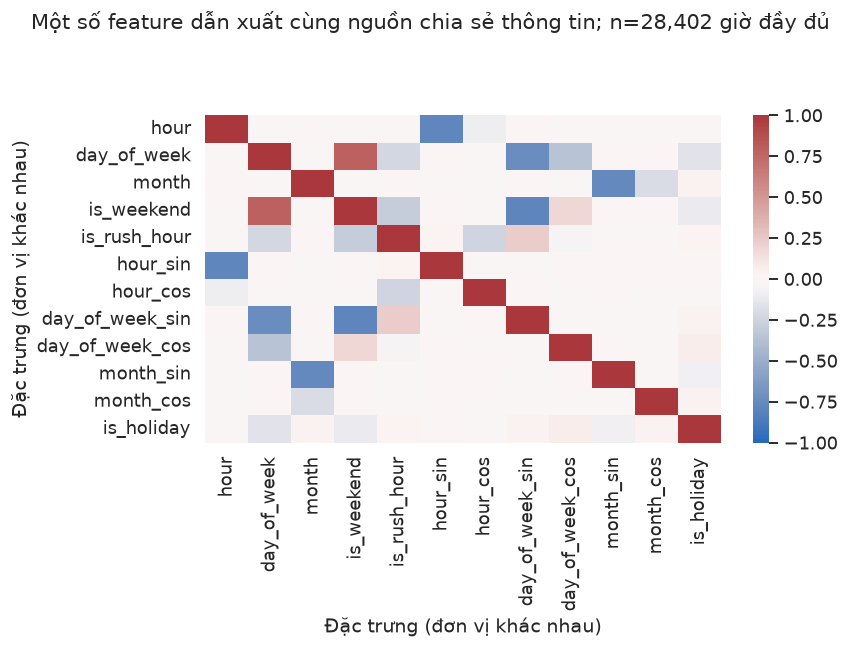

Màu thể hiện Pearson giữa các feature, không dùng để đánh giá liên hệ của mã giờ/thứ/tháng thô với target. Ô trống là hệ số không xác định, thường do biến hằng; không tự bỏ feature chỉ từ hình này.

In [16]:
eda_tools.corr_plot(context, 'A', corr_a, 5, len(train[CONFIG_A].dropna()))

## 6. Rủi ro rò rỉ và độ ổn định

In [17]:
display(eda_tools.stability(train, ['is_weekend', 'is_holiday', 'is_rush_hour']))

,year,feature,mean,missing_pct,n
0,2012,is_weekend,0.280552,0.0,2103
1,2012,is_holiday,0.045649,0.0,2103
2,2012,is_rush_hour,0.180219,0.0,2103
3,2013,is_weekend,0.285029,0.0,7294
4,2013,is_holiday,0.030436,0.0,7294
5,2013,is_rush_hour,0.176721,0.0,7294
6,2014,is_weekend,0.286603,0.0,4501
7,2014,is_holiday,0.020218,0.0,4501
8,2014,is_rush_hour,0.179293,0.0,4501
9,2015,is_weekend,0.283329,0.0,3593


Các feature lịch có thể biết trước. Nhãn lễ trong CSV có thể chưa đầy đủ; cần xác minh lịch khi triển khai. VIF cao chưa đủ để bỏ feature, nhất là với mô hình cây.

## 7. Quyết định

Giờ cao điểm khác nhau giữa ngày làm việc và cuối tuần. Khi đối chiếu cùng thứ và giờ, lưu lượng trung bình ngày lễ thấp hơn ngày thường; so sánh này chưa kiểm soát mùa và năm.

Đề xuất A12 làm mốc cho phần FE. Chưa bỏ riêng cột nào chỉ dựa vào tương quan hoặc VIF; mức đóng góp cho dự đoán sẽ được kiểm tra trong các notebook `notebooks/features/feaure_V*.ipynb`.

[Tài liệu API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html): TimeSeriesSplit mở rộng phần train; khi giờ bị thiếu, các fold cùng số hàng chưa chắc có cùng thời lượng lịch.
[pandas rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html) mô tả cửa sổ thời gian và `closed="left"`.
[Định nghĩa VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).